# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)

print("shape:", patients.shape)
display(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X("sessions_attended:Q", title="Sessions attended (of 36)"),
        y=alt.Y("walk_distance_m:Q",
                title="Six-minute walk distance (m)",
                scale=alt.Scale(zero=False)),
        color=alt.Color("program:N",
                scale=alt.Scale(domain=["Center-based", "Home-based"],
                                range=["#5E3C99", "#D63384"])),
        shape="program:N",
        tooltip=["patient_id", "sessions_attended", "walk_distance_m", "program"],
    )
    .properties(title="Walk distance rises with sessions attended")
)

exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

shape: (12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

The chart shows the relationship between how many sessions patients attended and how far they walked during the six-minute walk test. Each dot represents a patient, with the colors and shapes indicating whether they participated in the center-based or home-based program. In general, patients who attended more sessions were able to walk longer distances. For example, patients who attended around 10 sessions walked about 350 meters, compared with approximately 460 meters for those who attended 34 sessions. Center-based patients also tended to walk slightly farther than home-based patients with similar attendance. However, this does not mean that attending more sessions directly leads to better walking performance. Since the study only included 12 patients, other factors may have influenced the results. For instance, healthier or more motivated patients may be more likely to attend sessions and walk farther. It is also possible that patients who feel better are more likely to attend sessions, rather than attendance itself improving their walking ability.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


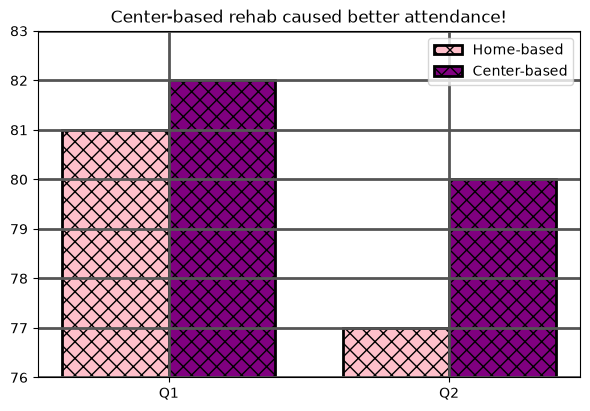

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="pink",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="purple",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim",
     "problem": "The title says center-based rehab 'caused' better attendance, but the chart only shows four attendance percentages (77 to 82%) with no comparison group or test, so it cannot show cause and effect. The gaps are only 1 to 3 points, and a reader could be misled into believing the program is the reason.",
     "repair": "Replace the title with a descriptive statement of what the data show, such as 'Attendance was similar across programs (77 to 82%)', with no causal wording."},
    {"category": "truncated baseline",
     "problem": "The y-axis starts at 76 and not 0, so the bar heights no longer match the values. The 77% home-based bar looks about a quarter the height of the 80% center-based bar, which exaggerates a 3-point gap and misleads readers about how big the difference is.",
     "repair": "Start the y-axis at 0 (or show the full 0 to 100% range) so bar length is proportional to attendance."},
    {"category": "missing unit",
     "problem": "The y-axis has no label, so a reader cannot tell that the values are the percent of sessions attended, and the numbers 76 to 83 could be read as counts or scores.",
     "repair": "Add the axis title 'Sessions attended (%)' so the unit and the measure are clear."},
    {"category": "color-only encoding",
     "problem": "The programs are told apart mainly by red versus green, which many color-blind readers cannot distinguish, and both bars use the same crosshatch pattern. In grayscale or a black-and-white printout, the two programs look nearly identical.",
     "repair": "Use a color-blind-safe palette with clearly different lightness, and add direct labels or a second cue (such as a different position or label) so the programs can be told apart without color."},
    {"category": "distracting decoration",
     "problem": "The thick black bar edges, crosshatch fill, and heavy dark grid lines carry no data. They add visual noise that pulls attention away from the bar heights and makes the values harder to read.",
     "repair": "Use plain solid fills with no hatching or outlines, and make the grid lines light and thin (or remove them) so the bars are the focus."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title says center-based rehab 'caused' better attendance, but the chart only shows four attendance percentages (77 to 82%) with no comparison group or test, so it cannot show cause and effect. The gaps are only 1 to 3 points, and a reader could be misled into believing the program is the reason.
    repair: Replace the title with a descriptive statement of what the data show, such as 'Attendance was similar across programs (77 to 82%)', with no causal wording.
truncated baseline: The y-axis starts at 76 and not 0, so the bar heights no longer match the values. The 77% home-based bar looks about a quarter the height of the 80% center-based bar, which exaggerates a 3-point gap and misleads readers about how big the difference is.
    repair: Start the y-axis at 0 (or show the full 0 to 100% range) so bar length is proportional to attendance.
missing unit: The y-axis has no label, so a reader cannot tell that the values are the percent of sessions attended, and the 

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

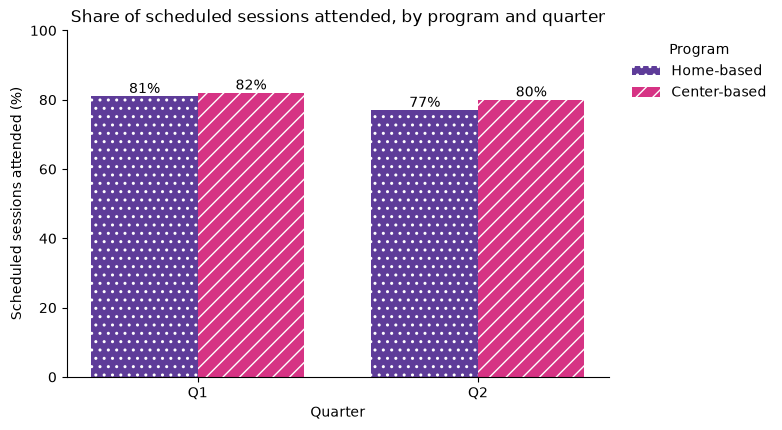

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(x - width / 2, home, width, label="Home-based",
                            color="#5E3C99", hatch="..", edgecolor="white", linewidth=0)
center_bars = redesign_ax.bar(x + width / 2, center, width, label="Center-based",
                              color="#D63384", hatch="//", edgecolor="white", linewidth=0)

redesign_ax.bar_label(home_bars, fmt="%d%%")
redesign_ax.bar_label(center_bars, fmt="%d%%")

redesign_ax.set_ylim(0, 100)
redesign_ax.set_xticks(x, quarters)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Share of scheduled sessions attended, by program and quarter")
redesign_ax.grid(False)
redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)
redesign_ax.legend(title="Program", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = "At each follow-up visit, what share of patients in the Home-based and Center-based programs met their goals, and how do the two programs compare?"
audience = "The rehabilitation program coordinator, who will use the chart to see whether either program needs more support at particular follow-up visits."
intended_claim = "The percent of patients meeting their goals rose at every follow-up visit in both programs, and it rose faster in the Center-based program (from 57% to 79%) than in the Home-based program (from 58% to 70%)."
y_measure = "Percent of patients who met their goals (%)"
grain = "One row is one program at one follow-up visit (for example, Home-based at visit 1), and one point on a line is the percent of that program's patients who met their goals at that visit."
data_types = {
    "program": "categorical",       
    "visit_number": "ordinal",      
    "goal_met_pct": "quantitative", 
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]]

supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

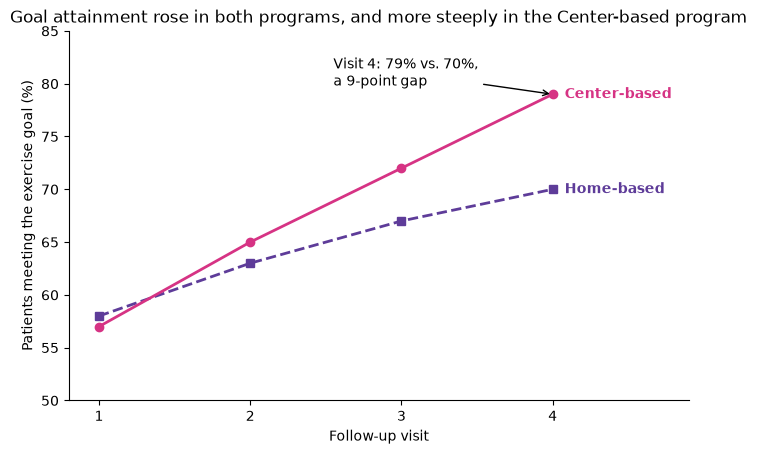

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(home_goals["visit_number"], home_goals["goal_met_pct"],
                    color="#5E3C99", marker="s", linestyle="--", linewidth=2, label="Home-based")
explanatory_ax.plot(center_goals["visit_number"], center_goals["goal_met_pct"],
                    color="#D63384", marker="o", linestyle="-", linewidth=2, label="Center-based")

explanatory_ax.text(4.08, 70, "Home-based", color="#5E3C99", va="center", fontweight="bold")
explanatory_ax.text(4.08, 79, "Center-based", color="#D63384", va="center", fontweight="bold")
explanatory_ax.annotate("Visit 4: 79% vs. 70%,\na 9-point gap",
                        xy=(4, 79), xytext=(2.55, 81),
                        arrowprops=dict(arrowstyle="->", color="black"),
                        va="center")

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_xlim(0.8, 4.9)
explanatory_ax.set_ylim(50, 85)
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_title("Goal attainment rose in both programs, and more steeply in the Center-based program")
explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)

explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = (
    "This line chart shows the percentage of patients meeting the exercise goal across four "
    "follow-up visits for the Home-based and Center-based programs. Both programs start at "
    "nearly the same percentage during visit 1, with 58% of Home-based patients and 57% of "
    "Center-based patients meeting the goal. The percentages increase at each visit for both "
    "groups. By visit 4, the Home-based group reaches 70%, while the Center-based group "
    "reaches 79%. This represents a 12-percentage-point increase for the Home-based group and "
    "a 22-point increase for the Center-based group. At the final visit, the Center-based "
    "group is 9 percentage points higher. However, these results do not necessarily mean that "
    "the Center-based program is more effective. Patients chose which program they wanted to "
    "participate in, so other factors may have influenced the results. Also, each percentage "
    "is based on only about 45 patients per group at each visit, so the difference could be "
    "due to chance or differences in which patients returned for follow-up."
)

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

1. Both programs can still be distinguished in grayscale in both charts. In the bar chart, the Home-based bars use a dotted pattern, while the Center-based bars have diagonal lines. The legend uses the same patterns to make them easy to identify. In the line chart, the Home-based program has a dashed line with square markers, while the Center-based program has a solid line with circle markers. Each line is also labeled at the end, so readers can tell them apart without relying on color.

2. The arrow points to the Center-based group's result at visit 4 (79%). The annotation says, "Visit 4: 79% vs. 70%, a 9-point gap," which simply describes the difference between the two groups. It does not suggest that one program caused better results. The title also describes the overall pattern, showing that both programs improved over time, but the Center-based group increased more.

3. Neither of the saved PNG charts has anything cut off or overlapping. In the bar chart, the legend is fully visible outside the plot on the right, and the line chart title fits within the image. Using bbox_inches="tight" when saving helped make sure that everything was included, so no additional changes were needed.

4. One limitation is that patients chose which program they wanted to participate in, so we cannot conclude that one program leads to better exercise outcomes. Other differences between patients could have influenced the results. Also, each percentage is based on only about 45 patients per group at each visit, and only includes those who returned for follow-up. This means the 9-point difference could be due to chance or differences in which patients came back. These limitations cannot be fixed by changing the charts because they are related to how the data were collected.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m